Optimized Weights (coef): [17.12265211  4.1378407   6.97209774 -1.94810406 -2.30775537 -0.95184008
  1.37511613  0.32304911 -0.08180264  0.47456788 -0.40195904  0.60425309
  0.4727892 ]
Mean Absolute Error: 5.9014
R² Score : 0.8262


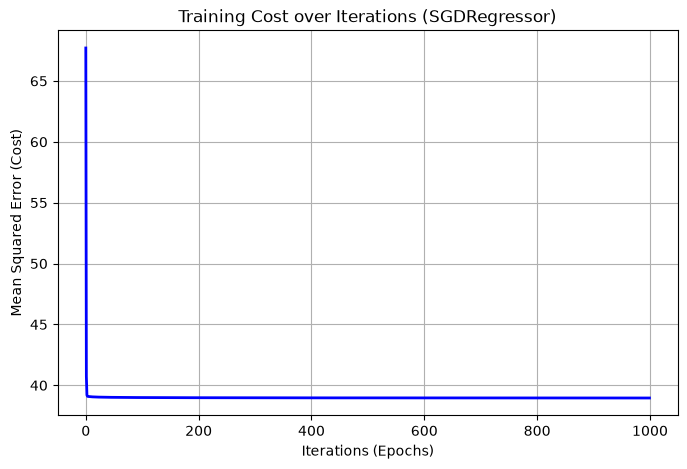

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load data
df = pd.read_csv("grid_restoration.csv")

y = df[["Restoration_Time_Minutes"]]
df = df.drop(columns=["Incident_ID", "Restoration_Time_Minutes"])

# 2. Handle missing values
df["Technician_Experience_Years"] = df["Technician_Experience_Years"].fillna(
    df["Technician_Experience_Years"].median()
)

for col in ["Fault_Category", "Grid_Load_Level", "Dispatch_Window"]:
  df[col] = df[col].fillna(df[col].mode()[0])

# 3. Encoding categorical variables
load_mapping = {"Low": 0, "Medium": 1, "High": 2}
df["Grid_Load_Level"] = df["Grid_Load_Level"].map(load_mapping)

df_encoded = pd.get_dummies(
    df, columns=["Fault_Category", "Dispatch_Window", "Crew_Type"], drop_first=True
)

bool_cols = df_encoded.select_dtypes(include=["bool"]).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

# 4. Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    df_encoded, y, test_size=0.20, random_state=42
)

# 5. Scale features separately so we can use partial_fit incrementally
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize SGDRegressor for incremental learning (max_iter=1 per partial_fit call)
sgd_model = SGDRegressor(
    alpha=0.0001,
    warm_start=True,
    max_iter=1,
    tol=None,  # Disable early stopping tol for manual iteration control
    eta0=0.01,
    random_state=42,
)

# 6. Iterative training loop & cost tracking
n_iterations = 1000
cost_history = []
y_train_flat = y_train.values.ravel()
y_test_flat = y_test.values.ravel()

for i in range(n_iterations):
  # partial_fit performs 1 epoch of SGD update on top of previous weights
  sgd_model.partial_fit(X_train_scaled, y_train_flat)

  # Compute predictions and MSE cost for test set
  y_pred = sgd_model.predict(X_test_scaled)
  cost = (
      mean_squared_error(y_test_flat, y_pred) / 2
  )  # Divided by 2 to match standard cost convention
  cost_history.append(cost)

# 7. Final Evaluation
mae = mean_absolute_error(y_test_flat, y_pred)
r2 = r2_score(y_test_flat, y_pred)

print(f"Optimized Weights (coef): {sgd_model.coef_}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"R² Score : {r2:.4f}")

# 8. Plot training cost over iterations
plt.figure(figsize=(8, 5))
plt.plot(range(n_iterations), cost_history, color="b", lw=2)
plt.title("Training Cost over Iterations (SGDRegressor)")
plt.xlabel("Iterations (Epochs)")
plt.ylabel("Mean Squared Error (Cost)")
plt.grid(True)
plt.show()

[38.92090738587415, 38.92090738587414, 38.92090738587414, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587412, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.92090738587415, 38.92090738587414, 38.920907385874145, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587412, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.92090738587415, 38.92090738587414, 38.920907385874145, 38.92090738587413, 38.92090738587413, 38.92090738587414, 38.92090738587413, 38.92090738587413, 38.920907385874145, 38.92090738587414, 38.92090738587414, 38.92090738587413, 38.9

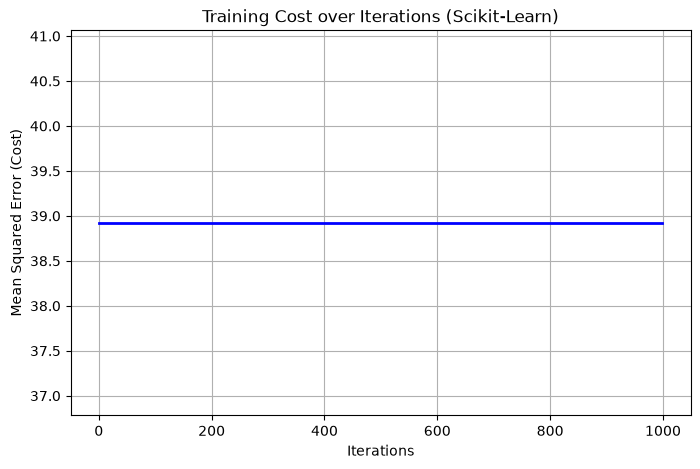

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score,mean_squared_error
import matplotlib.pyplot as plt

df = pd.read_csv('grid_restoration.csv')

y = df[['Restoration_Time_Minutes']]
df = df.drop(columns=['Incident_ID','Restoration_Time_Minutes'])





df['Technician_Experience_Years'] = df[
    'Technician_Experience_Years'
].fillna(df['Technician_Experience_Years'].median())

# Categorical columns
for col in ['Fault_Category', 'Grid_Load_Level', 'Dispatch_Window']:
    df[col] = df[col].fillna(df[col].mode()[0])







nominal_categorical_column = ['Fault_Category','Dispatch_Window','Crew_Type']



load_mapping = {"Low": 0, "Medium": 1, "High": 2}
#df["Grid_Load_Level_Encoded"] = df["Grid_Load_Level"].map(load_mapping)
df["Grid_Load_Level"] = df["Grid_Load_Level"].map(load_mapping)




df_encoded = pd.get_dummies(df,columns=['Fault_Category','Dispatch_Window','Crew_Type'],drop_first=True)


bool_cols = df_encoded.select_dtypes(include=['bool']).columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)




X_train, X_test, y_train, y_test = train_test_split(df_encoded,y,test_size=0.20,random_state=42 )



model = make_pipeline(StandardScaler(),SGDRegressor(alpha=0.0001,  warm_start=True , max_iter=1000,tol=None,eta0=0.01,random_state=42))

cost_history = []
for i in range(1000):

    
    model.fit(X_train, y_train.values.ravel())
    y_pred = model.predict(X_test)
    cost = mean_squared_error(y_test, y_pred) / 2  # Divided by 2 to match standard cost convention
    cost_history.append(cost)
print(cost_history)



mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Optimized Weights (coef): {model.named_steps["sgdregressor"].coef_}")

print(f"Mean Absolute Error: {mae:.4f}")
print(f"R² Score : {r2:.4f}")


plt.figure(figsize=(8, 5))
plt.plot(range(1000), cost_history, color="b", lw=2)
plt.title("Training Cost over Iterations (Scikit-Learn)")
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (Cost)")
plt.grid(True)
plt.show()

